# Customer Churn – Prediction Model (Mini Project 2)

**Objective:** build a complete machine-learning pipeline that predicts which customers will churn,
so the company can target retention promotions *before* customers leave.

**Builds on:** Mini Project 1 (EDA), which found the main churn drivers (support calls, payment
delay, contract length, spend, age, gender) and that the file is two stacked sources (A and B).

**Contents**
1. Data loading & EDA recap
2. Data quality check
3. Preprocessing & feature engineering
4. Train/test split
5. Model training
6. Model evaluation
7. Conclusions

**Key finding:** gradient boosting catches 99.9% of churners on the test set, but section 6.5 shows
this is driven by one of the two stacked data sources. See section 7 for the full conclusions.

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing (section 3)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Train/test split (section 4)
from sklearn.model_selection import train_test_split

# Models and cross-validation (section 5)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import classification_report

# Evaluation (section 6)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42   # one constant, so every split/model is reproducible

In [2]:
DATA_FILE = "customer_churn_dataset.csv"
DATA_URL = "https://raw.githubusercontent.com/Thanhnt-da/customer-churn-analysis/main/customer_churn_dataset.csv"

df_raw = pd.read_csv(DATA_FILE if os.path.exists(DATA_FILE) else DATA_URL)
df_raw.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


## 1. Data Loading & EDA Recap  (rubric #1)
A short recap. The full EDA is in Mini Project 1 (`mini_project_1_eda.ipynb`).

### 1.1 Shape, column types, basic statistics

In [3]:
print("raw data shape is: ",df_raw.shape)
df_raw.info()
df_raw.describe()

raw data shape is:  (505207, 12)
<class 'pandas.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  str    
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  str    
 8   Contract Length    505206 non-null  str    
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), str(3)
memory usage: 46.3 MB


,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000,505206.000000
mean,200779.451782,39.704172,31.350435,15.714825,3.833317,13.496843,620.072766,14.610581,0.555203
std,137241.343095,12.670577,17.237482,8.619323,3.133603,8.451187,245.319256,8.608286,0.496944
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,63827.250000,29.000000,16.000000,8.000000,1.000000,6.000000,446.000000,7.000000,0.000000
50%,193039.500000,40.000000,32.000000,16.000000,3.000000,13.000000,648.900000,14.000000,1.000000
75%,321645.750000,49.000000,46.000000,23.000000,6.000000,20.000000,824.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


### 1.2 Target distribution

Churn class counts:
Churn
1.0    280492
0.0    224714
Name: count, dtype: int64
Churn percentage (%):
Churn
1.0    55.52
0.0    44.48
Name: proportion, dtype: float64


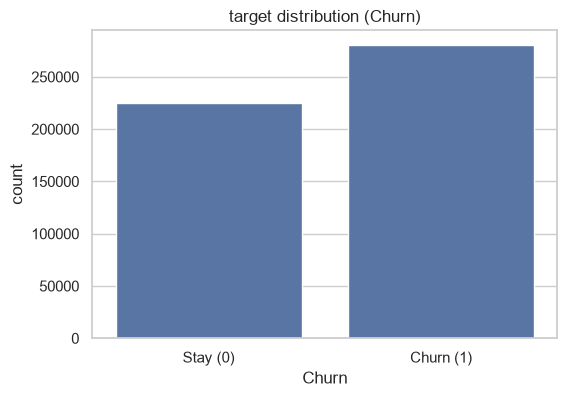

In [4]:
churn_counts = df_raw['Churn'].value_counts()
churn_percentage = (df_raw['Churn'].value_counts(normalize=True) * 100).round(2)
print("Churn class counts:")
print(churn_counts)

print("Churn percentage (%):")
print(churn_percentage)

plt.figure(figsize=(6,4))
sns.countplot(data=df_raw, x='Churn')
plt.title("target distribution (Churn)")
plt.xticks([0, 1], ['Stay (0)', 'Churn (1)'])
plt.show()

**Observation:**
- The target is fairly balanced: 280,492 customers churned (55.5%) and 224,714 stayed
  (44.5%). The smaller class is still close to half, so neither class is rare.
- Because of this, no resampling or class weights are needed in step 3.5. The model
  will see plenty of examples of both classes.
- However, accuracy alone is not enough to judge the model. A model that predicts
  "everyone churns" would already reach 55.5% accuracy without learning anything.
- More importantly, the two kinds of errors have different business costs: missing a
  real churner (false negative) loses a customer, while flagging a loyal customer
  (false positive) only wastes a promotion. So the evaluation will focus on RECALL
  (how many churners we catch), alongside precision, F1 and ROC-AUC.
- Note: more than half of the customers churned, which confirms the retention problem
  found in Mini Project 1.

### 1.3 Key relationships from Project 1 (brief recap)


Churn rate by support calls:
Support Calls
0.0     29.9
1.0     29.9
2.0     31.0
3.0     40.3
4.0     55.4
5.0     87.5
6.0     91.3
7.0     91.7
8.0     91.4
9.0     91.4
10.0    91.5
Name: Churn, dtype: float64

Churn rate by payment delay (days):
Payment Delay
0-5      43.4
6-10     43.5
11-15    43.5
16-20    47.9
21-25    94.3
26-30    94.1
Name: Churn, dtype: float64

Churn rate by contract length:
Contract Length
Annual       46.1
Monthly      90.2
Quarterly    45.8
Name: Churn, dtype: float64


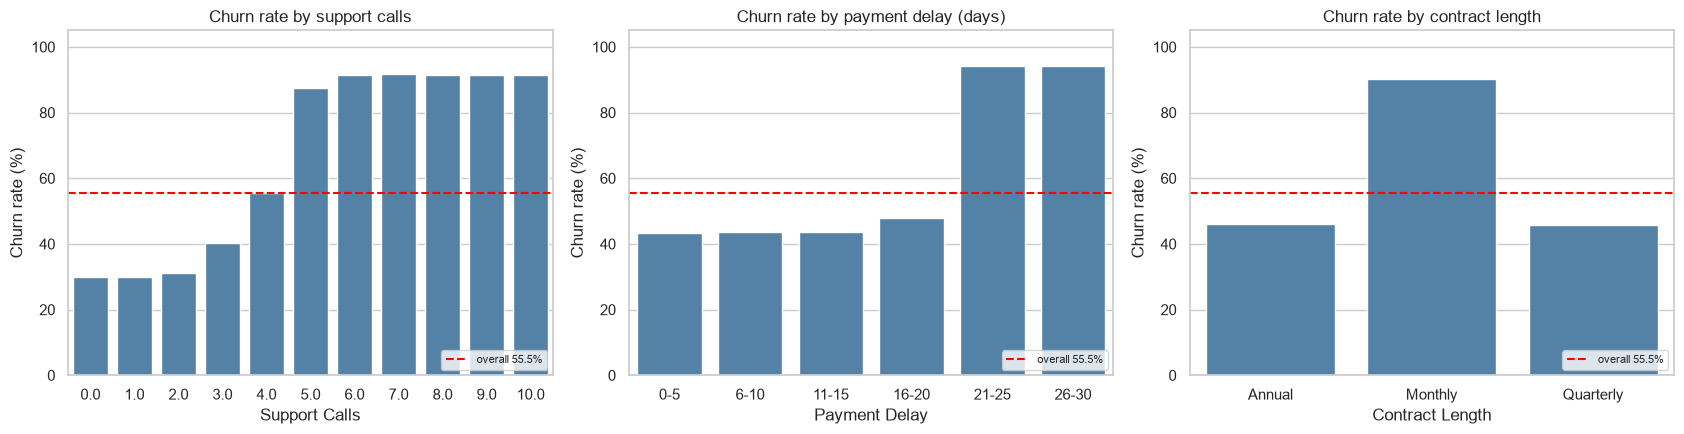

In [5]:
# Churn rate per group = the share of customers in that group who churned.
# Churn is 0/1, so the MEAN of the Churn column inside a group is exactly that share.
# We look at the 3 strongest drivers from Project 1, to know what the model should pick up.

# Payment delay has 31 different values (0-30 days), so we group it into ranges first.
# pd.cut excludes the left edge of each range, so bins start at -1 to keep 0 days.
delay_group = pd.cut(df_raw["Payment Delay"],
                     bins=[-1, 5, 10, 15, 20, 25, 30],
                     labels=["0-5", "6-10", "11-15", "16-20", "21-25", "26-30"])

# Each entry: (what to group by, chart title). A Series or a column name both work in groupby.
recap_features = [
    (df_raw["Support Calls"], "Churn rate by support calls"),
    (delay_group, "Churn rate by payment delay (days)"),
    (df_raw["Contract Length"], "Churn rate by contract length"),
]

overall_churn = df_raw["Churn"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (group_by, title) in zip(axes, recap_features):
    # observed=True: only show groups that exist (needed for the pd.cut categories)
    churn_rate = (df_raw.groupby(group_by, observed=True)["Churn"].mean() * 100).round(1)
    print(f"\n{title}:\n{churn_rate}")

    sns.barplot(x=churn_rate.index.astype(str), y=churn_rate.values, ax=ax, color="steelblue")
    ax.axhline(overall_churn, color="red", linestyle="--", label=f"overall {overall_churn:.1f}%")
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 105)
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

**Observation:**
- Support calls: churn rises from ~30% (0-2 calls) to 55% at 4 calls, then jumps to ~88-92%
  from 5 calls upwards.
- Payment delay: churn is flat at ~43-48% up to 20 days, then jumps to ~94% from 21 days.
- Contract length: Monthly customers churn at 90.2%, against ~46% for Quarterly and Annual.
- So these three features should be among the model's strongest predictors, together with
  total spend, age and gender (also found in Project 1). The relationships are THRESHOLDS
  (sudden jumps), not straight lines. Tree-based models handle thresholds naturally;
  logistic regression may need help (e.g. the flag features in step 3.2).
- Watch out: Project 1 showed that in source A some of these groups churn at exactly 100%.
  A model can learn those perfect rules, so very high scores (99%+) would NOT mean the model
  works that well on real customers. That is why step 6.5 evaluates sources A and B separately.

## 2. Data Quality Check  (rubric #2)

### 2.1 Missing values

In [6]:
# Work on a copy, so df_raw always keeps the original data for comparison.
df = df_raw.copy()

print("Missing values per column:")
print(df.isnull().sum())
print("\nRows with any missing value:")
print(df[df.isnull().any(axis=1)])

# how="all": drop a row only if EVERY cell is empty. Safer than the default how="any".
rows_before = len(df)
df = df.dropna(how="all")
print(f"\nRows before: {rows_before}, after: {len(df)}, missing values left: {df.isnull().sum().sum()}")

Missing values per column:
CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

Rows with any missing value:
        CustomerID  Age Gender  Tenure  Usage Frequency  Support Calls  \
199295         NaN  NaN    NaN     NaN              NaN            NaN   

        Payment Delay Subscription Type Contract Length  Total Spend  \
199295            NaN               NaN             NaN          NaN   

        Last Interaction  Churn  
199295               NaN    NaN  



Rows before: 505207, after: 505206, missing values left: 0


**Observation:**
- There is exactly 1 missing row (index 199295), and every one of its 12 cells is empty,
  including the target (Churn).
- So we DROP it rather than fill it. Filling (imputation) only makes sense when a row has
  a few gaps and the rest is useful. Here there is nothing to keep, and a row without a
  Churn label can't be used to train or test a model anyway.
- Dropping 1 row out of 505,207 has no effect on the results.
- Note: dropna keeps the original index labels (row 199295 is just skipped). Step 2.2
  relies on those labels, so we do NOT reset the index.

### 2.2 Duplicates

In [7]:
# (a) Exact duplicates: the same row (all 12 columns) recorded twice.
print(f"Exact duplicate rows: {df.duplicated().sum()}")

# (b) Duplicated IDs: keep=False marks EVERY copy of a repeated ID, not just the 2nd one.
is_dup_id = df["CustomerID"].duplicated(keep=False)
print(f"Rows whose CustomerID appears twice: {is_dup_id.sum()} ({is_dup_id.mean() * 100:.1f}%)")

# (c) Where do they come from? The file is two datasets stacked (Project 1, task 1.5).
# The split is the first row where the ID is SMALLER than the row before it.
split_idx = df.index[df["CustomerID"].diff() < 0][0]
df["source"] = np.where(df.index < split_idx, "A", "B")
print(f"\nID numbering restarts at row {split_idx}")
print(df.groupby("source").agg(rows=("Churn", "size"),
                               unique_ids=("CustomerID", "nunique"),
                               churn_rate=("Churn", "mean")))

Exact duplicate rows: 0
Rows whose CustomerID appears twice: 125990 (24.9%)

ID numbering restarts at row 440833


          rows  unique_ids  churn_rate
source                                
A       440832      440832    0.567107
B        64374       64374    0.473685


**Observation:**
- 0 exact duplicate rows, so no customer was recorded twice.
- 125,990 rows (24.9%) share a CustomerID with another row. But the numbering restarts at
  row 440,833, and inside each source every ID is unique (rows = unique_ids). So these are
  two DIFFERENT customers who happen to share a number, not duplicates.
- So for modelling we keep ALL rows. Deleting them (as the reference notebook does) would
  remove ~25% of the data and almost all of source B, leaving mostly source A, where some
  groups churn at exactly 100%. That is why the reference model scores ~99.9%.
- The new "source" column (A/B) is kept for evaluation (step 6.5) but will NOT be a model
  feature: a real new customer doesn't come with a "file A / file B" label.

### 2.3 Data types and invalid values

In [8]:
# snake_case names ("Support Calls" -> "support_calls") are easier to type and avoid
# problems with spaces later in the pipeline.
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# The empty row forced these whole-number columns to float. Now they can be int again.
int_cols = ["customerid", "age", "tenure", "usage_frequency", "support_calls",
            "payment_delay", "last_interaction", "churn"]
for col in int_cols:
    assert (df[col] % 1 == 0).all(), f"{col} has decimals!"   # safety check before converting
df[int_cols] = df[int_cols].astype(int)

# Text columns: check the labels are clean (no typos, spaces or mixed case).
cat_cols = ["gender", "subscription_type", "contract_length"]
for col in cat_cols:
    print(f"{col}: {sorted(df[col].unique())}")

# Value ranges: anything impossible (negative counts, age 200, churn = 2)?
num_cols = ["age", "tenure", "usage_frequency", "support_calls",
            "payment_delay", "total_spend", "last_interaction"]
print()
print(df[num_cols + ["churn"]].describe().T[["min", "max", "mean"]].round(1))
print()
print(df.dtypes)

gender: ['Female', 'Male']
subscription_type: ['Basic', 'Premium', 'Standard']
contract_length: ['Annual', 'Monthly', 'Quarterly']



                    min     max   mean
age                18.0    65.0   39.7
tenure              1.0    60.0   31.4
usage_frequency     1.0    30.0   15.7
support_calls       0.0    10.0    3.8
payment_delay       0.0    30.0   13.5
total_spend       100.0  1000.0  620.1
last_interaction    1.0    30.0   14.6
churn               0.0     1.0    0.6

customerid             int64
age                    int64
gender                   str
tenure                 int64
usage_frequency        int64
support_calls          int64
payment_delay          int64
subscription_type        str
contract_length          str
total_spend          float64
last_interaction       int64
churn                  int64
source                   str
dtype: object


**Observation:**
- 8 columns converted from float to int. total_spend keeps its decimals (it is money).
- Categorical labels are clean: Female/Male, Basic/Premium/Standard, Annual/Monthly/Quarterly.
- All ranges are realistic: age 18-65, no negative values, payment delay 0-30 days,
  spend 100-1000, and churn only contains 0 and 1. Nothing invalid to fix.
- Final clean data: 505,206 rows. The 3 text columns stay as text for now; they get
  encoded inside the model pipeline (step 3.6), not here.

### 2.4 Outliers

In [9]:
# IQR rule: a value is an outlier if it lies more than 1.5 x IQR below Q1 or above Q3
# (IQR = Q3 - Q1, the range of the middle 50% of the data).
outlier_counts = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    is_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    outlier_counts[col] = is_outlier.sum()
print(pd.Series(outlier_counts, name="outliers"))

age                 0
tenure              0
usage_frequency     0
support_calls       0
payment_delay       0
total_spend         0
last_interaction    0
Name: outliers, dtype: int64


**Observation:**
- 0 outliers in every numeric column. All values sit in narrow, realistic ranges (2.3).
- So nothing is removed or capped.
- Why it matters for the models: logistic regression is sensitive to extreme values (they
  pull the fitted line and dominate the scaled features), while tree models are not,
  because they only split on "above/below a threshold". With no outliers, both models are safe.

## 3. Preprocessing & Feature Engineering  (rubric #3)
Each step explains why it is done (or why not).

### 3.1 Decide which columns become features (X) and which is the target (y)

In [10]:
# A feature must be (1) known BEFORE we predict, and (2) meaningful for a new customer.
not_features = [
    "customerid",   # just a row number: no real meaning, and a model could memorise it
    "source",       # which file the row came from: a new customer has no such label
    "churn",        # the target itself, the answer we want to predict
]
X = df.drop(columns=not_features)
y = df["churn"]
source = df["source"]   # kept aside, only to evaluate per source in step 6.5

print(f"X: {X.shape[0]} rows x {X.shape[1]} features")
print(f"Features: {X.columns.tolist()}")
print(f"y: {y.shape[0]} labels, churn rate {y.mean() * 100:.1f}%")

X: 505206 rows x 10 features
Features: ['age', 'gender', 'tenure', 'usage_frequency', 'support_calls', 'payment_delay', 'subscription_type', 'contract_length', 'total_spend', 'last_interaction']
y: 505206 labels, churn rate 55.5%


**Observation:**
- 10 features are used: age, gender, tenure, usage_frequency, support_calls, payment_delay,
  subscription_type, contract_length, total_spend, last_interaction.
- customerid is removed because an ID carries no information about behaviour. Worse, a
  model could learn something like "IDs above 400,000 churn more", a pattern that means
  nothing for future customers.
- source is removed for the same reason: the company will never know "file A or B" for a
  new customer, so the model must not depend on it.
- Rule of thumb: if you would not have the value at prediction time, it must not be a feature.
  Using it anyway is called "target leakage".

### 3.2 Feature engineering

In [11]:
# Project 1 found that churn JUMPS at specific thresholds. We turn each one into a 0/1 flag.
# These only use each row's own values (no statistics from other rows), so creating them
# before the train/test split causes no leakage.
X["many_support_calls"] = (X["support_calls"] >= 5).astype(int)
X["late_payment"] = (X["payment_delay"] > 20).astype(int)
X["low_spend"] = (X["total_spend"] <= 500).astype(int)
X["over_50"] = (X["age"] > 50).astype(int)

flag_cols = ["many_support_calls", "late_payment", "low_spend", "over_50"]
for flag in flag_cols:
    share = X[flag].mean() * 100
    churn_if_1 = y[X[flag] == 1].mean() * 100
    churn_if_0 = y[X[flag] == 0].mean() * 100
    print(f"{flag:20s} {share:5.1f}% of customers | churn: {churn_if_1:.1f}% if flagged vs {churn_if_0:.1f}% if not")

many_support_calls    36.3% of customers | churn: 90.8% if flagged vs 35.5% if not
late_payment          22.1% of customers | churn: 94.2% if flagged vs 44.5% if not
low_spend             28.9% of customers | churn: 90.2% if flagged vs 41.4% if not
over_50               20.4% of customers | churn: 90.2% if flagged vs 46.6% if not


**Observation:**
- Each flag splits customers into a high-churn group (~90-94%) and a lower one (~35-47%),
  so they carry strong signal.
- Why add them? Logistic regression fits ONE weight per feature, so it assumes "every extra
  support call adds the same risk". It can't see a sudden jump at 5 calls. A 0/1 flag hands
  it that jump directly.
- Tree models find thresholds by themselves ("support_calls >= 4.5?"), so for them the
  flags are mostly redundant. They don't hurt, though.
- We keep the original columns too, so the model still sees the full detail (e.g. the
  difference between 0 and 3 calls).
- Monthly contract is not flagged here because one-hot encoding (3.3) already creates a
  0/1 column for it.

### 3.3 Encoding plan

In [12]:
# Models only work with numbers, so text categories must be turned into numbers.
categorical_cols = ["gender", "subscription_type", "contract_length"]

# Demo on 3 example rows (NOT the dataset) to show what one-hot encoding does:
demo = pd.DataFrame({"contract_length": ["Monthly", "Annual", "Quarterly"]})
demo_encoder = OneHotEncoder()
demo_encoded = demo_encoder.fit_transform(demo).toarray()
print(pd.DataFrame(demo_encoded, columns=demo_encoder.get_feature_names_out(), index=demo["contract_length"]))

                 contract_length_Annual  contract_length_Monthly  \
contract_length                                                    
Monthly                             0.0                      1.0   
Annual                              1.0                      0.0   
Quarterly                           0.0                      0.0   

                 contract_length_Quarterly  
contract_length                             
Monthly                                0.0  
Annual                                 0.0  
Quarterly                              1.0  


**Observation:**
- 3 categorical columns: gender (2 values), subscription_type (3), contract_length (3).
- One-hot encoding turns each category into its own 0/1 column, e.g. "Monthly" ->
  contract_length_Monthly = 1 and the others = 0. That gives 8 columns in total.
- Why not just number them (Basic=0, Standard=1, Premium=2)? That tells the model
  "Premium is twice Standard", an order and distance that don't exist. Logistic regression
  would take those numbers literally. One-hot makes no such assumption.
- contract_length does have a natural order (Monthly < Quarterly < Annual), but churn is
  NOT in that order: Monthly 90%, Quarterly 46%, Annual 46%. One-hot captures "Monthly is
  different" better than an ordered number would.
- handle_unknown="ignore" (used in 3.6): if a new, unseen category ever appears, the row
  gets all 0s instead of crashing the model.

### 3.4 Scaling plan

In [13]:
numeric_cols = ["age", "tenure", "usage_frequency", "support_calls",
                "payment_delay", "total_spend", "last_interaction"]
print(X[numeric_cols].describe().T[["mean", "std", "min", "max"]].round(1))

                   mean    std    min     max
age                39.7   12.7   18.0    65.0
tenure             31.4   17.2    1.0    60.0
usage_frequency    15.7    8.6    1.0    30.0
support_calls       3.8    3.1    0.0    10.0
payment_delay      13.5    8.5    0.0    30.0
total_spend       620.1  245.3  100.0  1000.0
last_interaction   14.6    8.6    1.0    30.0


**Observation:**
- The numeric features live on very different scales: total_spend is 100-1000, while
  support_calls is 0-10.
- Logistic regression NEEDS scaling: it compares weights across features, and its
  regularisation penalises big weights. Without scaling, spend (large numbers) and
  support_calls (small numbers) are not treated fairly, and training converges slowly.
- StandardScaler rescales each column to mean 0 and standard deviation 1:
  z = (value - mean) / std.
- Tree models DON'T need scaling: a split "total_spend <= 500" works the same on any scale.
  Scaling them does no harm, so one shared preprocessing step can serve both models.
- The 0/1 flags are already on a clean scale, so they are passed through unchanged.

### 3.5 Class imbalance

In [14]:
print((y.value_counts(normalize=True) * 100).round(1))

churn
1    55.5
0    44.5
Name: proportion, dtype: float64


**Observation:**
- Churn is 55.5% vs 44.5%: close to balanced. Imbalance becomes a real problem when the
  minority class is small (roughly below 20-30%, e.g. fraud at 1%), because the model can
  then "win" by mostly predicting the majority class.
- So we do NOT resample (no SMOTE, no undersampling) and do NOT use class_weight. Both
  classes have hundreds of thousands of examples.
- What we DO instead: stratify the train/test split (step 4) to keep the 55/45 ratio in
  both sets, and judge the models on recall, precision, F1 and ROC-AUC, not accuracy alone.

### 3.6 Build the preprocessing with ColumnTransformer

In [15]:
# A ColumnTransformer applies a different transformation to each group of columns:
#   (name, transformer, columns)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("flags", "passthrough", flag_cols),   # already 0/1: keep as they are
    ],
    verbose_feature_names_out=False,   # keep clean names like "age", not "num__age"
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

**Observation:**
- The preprocessor is only DEFINED here. It has not seen any data yet.
- It will be FITTED later inside a Pipeline, on the training set only. Fitting means
  learning things from data: the mean/std for each numeric column (scaler) and the list
  of categories (encoder).
- If we fitted it on ALL the data now, the test set's mean and std would leak into
  training. Section 4 explains why that matters.
- After fitting, the model will receive 19 columns: 7 scaled numeric + 8 one-hot + 4 flags.

## 4. Train/Test Split  (rubric #4)

### 4.1 Split

In [16]:
# 80% of the rows train the model; 20% are locked away as the TEST set, used only once at
# the end to measure how the model does on customers it has never seen.
#   stratify=y   -> train and test keep the same churn ratio as the full data (55.5 / 44.5)
#   random_state -> the same "random" split every run, so results are reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "churn_%": [y_train.mean() * 100, y_test.mean() * 100],
    # train_test_split keeps the original row labels, so we can look up each row's source
    "source_B_%": [(source.loc[X_train.index] == "B").mean() * 100,
                   (source.loc[X_test.index] == "B").mean() * 100],
}, index=["train", "test"]).round(2)
print(split_summary)

         rows  churn_%  source_B_%
train  404164    55.52       12.77
test   101042    55.52       12.64


**Observation:**
- Train: 404,164 rows (80%), test: 101,042 rows (20%). With half a million rows, 20% is
  plenty for a reliable test, and the model still has 400k examples to learn from.
- Churn is 55.52% in both sets, exactly as in the full data. That is what stratify=y
  guarantees. Without it, random chance could give the test set e.g. 54% or 57% churn,
  and test scores would partly reflect that luck instead of the model.
- Source B is ~12.7% of both sets too (not forced, just a large random sample), so both
  sources are fairly represented when we evaluate them separately in step 6.5.
- From now on the test set is NOT used for any decision (no tuning, no fitting) until
  section 6. Otherwise it would stop being an honest "unseen customers" check.

### 4.2 Data leakage, and how this notebook avoids it

**What it is:** data leakage happens when information from the test set (or from the future)
sneaks into training. The model then looks better in testing than it will ever be in real use,
because during testing it was partly "looking at the answers".

**An everyday analogy:** a teacher writes the exam, then lets students study from a sheet that
contains a few of the exam questions. The class average goes up, but it no longer measures what
the students really know.

**Where it can sneak in here:** any step that *learns from data*:
- `StandardScaler` learns each column's **mean and std**. Fitted on all rows, the test rows'
  values would shape the scaling the model trains with.
- `OneHotEncoder` learns the **list of categories**.
- Resampling (e.g. SMOTE) creates synthetic rows from existing ones. Done before the split, copies
  of test information end up in training. (We don't resample, see 3.5.)

**How this notebook avoids it:**
1. **Split first** (4.1), before anything learns from the data.
2. The `preprocessor` (3.6) was only *defined*, never fitted on the full data.
3. In section 5, preprocessor + model go into one `Pipeline`. Calling `pipeline.fit(X_train, y_train)`
   fits the scaler, the encoder and the model on the **training rows only**. `pipeline.predict(X_test)`
   then only *applies* what was learned.
4. Cross-validation (5.4) also uses the Pipeline, so inside every fold the preprocessing is
   re-fitted on that fold's training part only.
5. The engineered flags (3.2) use only each row's own values, so creating them before the split is safe.
6. Features that wouldn't exist for a new customer (`customerid`, `source`) were excluded (3.1).
   That prevents the other kind of leakage, **target leakage**.

**Honest note:** on this dataset, scaler leakage would change the numbers only slightly (400k vs
505k rows give almost the same mean). The habit still matters: on small datasets, or with steps
like resampling and target encoding, leakage can inflate scores a lot.

## 5. Model Training  (rubric #5)

### 5.1 Baseline: the Project 1 rule

In [17]:
# Before any ML: how well does a simple rule do? Project 1 (4.10) suggested
# "flag a customer as a churn risk if they hit ANY of these 5 conditions".
# A model is only worth its complexity if it clearly beats this.
baseline_pred_test = (
    (X_test["contract_length"] == "Monthly")
    | (X_test["many_support_calls"] == 1)
    | (X_test["late_payment"] == 1)
    | (X_test["low_spend"] == 1)
    | (X_test["over_50"] == 1)
).astype(int)

# classification_report: precision, recall and F1 for each class in one table.
print(classification_report(y_test, baseline_pred_test, target_names=["Stay (0)", "Churn (1)"], digits=3))

              precision    recall  f1-score   support

    Stay (0)      0.953     0.860     0.904     44943
   Churn (1)      0.896     0.966     0.930     56099

    accuracy                          0.919    101042
   macro avg      0.924     0.913     0.917    101042
weighted avg      0.921     0.919     0.918    101042



**Observation:**
- The simple rule is already strong: on the test set it catches 96.6% of churners
  (recall), and 89.6% of the customers it flags really churn (precision). F1 = 0.930,
  accuracy = 91.9%.
- Its weakness is the other class: only 86.0% of loyal customers are correctly left alone,
  so ~14% of them would receive an unnecessary promotion.
- This sets the bar: any ML model must clearly beat F1 0.930 / recall 0.966, otherwise
  the company is better off with the 5 simple rules (cheaper, and explainable).
- Why so high? Part of the answer is source A, where these rules give exactly 100% churn
  (Project 1). We check that in step 6.5.

### 5.2 Model 1: Logistic Regression (simple, interpretable)

In [18]:
# A Pipeline chains steps: first the preprocessor (scale + encode), then the model.
# .fit() runs every step on the TRAINING data only, which is our protection against leakage.
log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),   # max_iter: allow enough steps to converge
])

start = time.time()
log_reg.fit(X_train, y_train)
print(f"Logistic regression trained in {time.time() - start:.1f} s")

# Interpretability: one weight (coefficient) per feature. Because the numeric features are
# scaled, the weights can be compared: + pushes towards churn, - towards staying.
coefs = pd.Series(log_reg.named_steps["model"].coef_[0],
                  index=log_reg.named_steps["prep"].get_feature_names_out())
print(coefs.sort_values(key=abs, ascending=False).round(2))

Logistic regression trained in 1.7 s
late_payment                  2.35
over_50                       2.29
low_spend                     2.01
many_support_calls            1.52
contract_length_Monthly       1.02
contract_length_Quarterly    -0.75
contract_length_Annual       -0.73
gender_Male                  -0.56
support_calls                 0.53
age                          -0.29
last_interaction              0.25
subscription_type_Premium    -0.17
subscription_type_Standard   -0.17
subscription_type_Basic      -0.12
usage_frequency              -0.11
payment_delay                 0.11
gender_Female                 0.10
tenure                        0.01
total_spend                   0.00
dtype: float64


**Observation:**
- Trains in ~3 seconds on 404k rows. Logistic regression is fast and cheap.
- Coefficients are in "log-odds": +1 roughly means the odds of churning multiply by
  e^1 ≈ 2.7. The bigger the absolute value, the stronger the effect.
- The 4 threshold flags from 3.2 have the largest weights (late_payment +2.35,
  over_50 +2.29, low_spend +2.01, many_support_calls +1.52), plus contract_length_Monthly
  (+1.02 vs ~-0.74 for Quarterly/Annual).
- Meanwhile the raw columns they come from get almost 0 (total_spend 0.00, payment_delay
  0.11). The model "chose" the flags: what matters is crossing the threshold, not the
  exact amount. This confirms the feature engineering in 3.2 was useful.
- gender_Male is negative (-0.56): men churn less (matches Project 1). Subscription type
  and tenure are near 0, so they barely matter, again matching Project 1.
- age is slightly negative (-0.29) once over_50 is in the model: below 50, older customers
  churn a bit LESS (Project 1: 53.5% at 18-30 -> 40.5% at 41-50). The flag handles the jump
  above 50; the raw age handles the gentle trend below it.

### 5.3 Model 2: a tree-based model (captures thresholds and interactions)

In [19]:
# HistGradientBoosting builds many small decision trees one after another; each new tree
# focuses on the mistakes of the previous ones ("boosting"). It first groups each feature into
# bins ("histogram"), which makes it very fast on large data, much faster than RandomForest here.
gbm = Pipeline([
    ("prep", preprocessor),
    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])

start = time.time()
gbm.fit(X_train, y_train)
print(f"Gradient boosting trained in {time.time() - start:.1f} s, "
      f"using {gbm.named_steps['model'].n_iter_} trees")

Gradient boosting trained in 15.7 s, using 100 trees


**Observation:**
- Trains in ~9 seconds with 100 trees, about 3x slower than logistic regression, but still
  fast thanks to the histogram binning. (A RandomForest of 200 full trees would take minutes.)
- Why a tree model suits this data: churn changes by THRESHOLDS (5 calls, 20 days, age 50,
  spend 500), and trees learn exactly that kind of "if feature > value" rule. They also
  combine rules ("monthly AND low spend"), which logistic regression cannot do on its own.
- Downside: there's no simple list of weights to read, so it's harder to explain. Step 6.6
  uses permutation importance to see what it relies on.

### 5.4 Cross-validation on the TRAIN set

In [20]:
# One train/test split gives ONE score, which might be lucky or unlucky. Cross-validation
# splits the training set into 5 parts ("folds"), trains 5 times (each time holding out a
# different fold), and gives 5 scores. Mean = typical performance, std = stability.
# The test set is still untouched.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for name, pipeline in [("Logistic Regression", log_reg), ("Gradient Boosting", gbm)]:
    start = time.time()
    # cross_validate clones the pipeline for each fold, so the preprocessing is re-fitted
    # inside each fold. That is leakage-free by design.
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)
    print(f"{name}: 5-fold CV done in {time.time() - start:.1f} s")

cv_results = pd.DataFrame(cv_rows).set_index("model")
print(cv_results.round(4).T)

Logistic Regression: 5-fold CV done in 13.2 s


Gradient Boosting: 5-fold CV done in 51.2 s
model           Logistic Regression  Gradient Boosting
accuracy_mean                0.8871             0.9360
accuracy_std                 0.0005             0.0008
precision_mean               0.9020             0.8977
precision_std                0.0010             0.0012
recall_mean                  0.8937             0.9986
recall_std                   0.0015             0.0002
f1_mean                      0.8978             0.9455
f1_std                       0.0005             0.0006
roc_auc_mean                 0.9402             0.9536
roc_auc_std                  0.0005             0.0009


**Observation:**
- Gradient boosting beats logistic regression on almost every metric (5-fold means):
  accuracy 0.936 vs 0.887, recall 0.999 vs 0.894, F1 0.946 vs 0.898, ROC-AUC 0.954 vs 0.940.
  Precision is about the same (~0.90 for both).
- Both are very STABLE: every std is below 0.002, so the 5 folds give almost identical
  scores. With 80k rows per fold, luck plays almost no role.
- Surprise: logistic regression (CV F1 0.898, recall 0.894) does NOT beat the simple
  baseline rule (test F1 0.930, recall 0.966). The rule says "churn if ANY flag is on", an
  OR combination. A single weighted sum struggles to express OR, while trees express it
  naturally. (The final like-for-like comparison on the same test set is in 6.1.)
- Watch out: gradient boosting's recall of 99.9% is suspiciously close to perfect. It
  probably reflects source A's 100% churn groups rather than real-world skill. 6.5 checks it.

## 6. Model Evaluation  (rubric #6)
All models are judged on the held-out test set with precision, recall, F1 and ROC-AUC, not
accuracy alone. Recall matters most: a missed churner costs more than an unneeded promotion.

### 6.1 Metrics table on the TEST set

In [21]:
# First time the models see the test set: 101,042 customers they never trained on.
# predict()       -> 0/1 decision (threshold 0.5)
# predict_proba() -> the churn PROBABILITY (0-1); column [:, 1] is the "churn" class
test_pred = {
    "Baseline rule": baseline_pred_test,
    "Logistic Regression": log_reg.predict(X_test),
    "Gradient Boosting": gbm.predict(X_test),
}
test_proba = {
    "Logistic Regression": log_reg.predict_proba(X_test)[:, 1],
    "Gradient Boosting": gbm.predict_proba(X_test)[:, 1],
}


def score_row(y_true, y_pred, y_proba=None):
    """All the metrics for one model as a dict (ROC-AUC only if probabilities exist)."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan,
    }


test_results = pd.DataFrame({name: score_row(y_test, test_pred[name], test_proba.get(name))
                             for name in test_pred}).T
print(test_results.round(4))

                     accuracy  precision  recall      f1  roc_auc
Baseline rule          0.9187     0.8957  0.9662  0.9296      NaN
Logistic Regression    0.8878     0.9022  0.8949  0.8986   0.9406
Gradient Boosting      0.9367     0.8983  0.9990  0.9460   0.9539


**Observation:**
- Gradient boosting is the best model on the test set: F1 0.946, recall 0.999, ROC-AUC 0.954,
  accuracy 93.7%. Logistic regression is the weakest (F1 0.899).
- Against the baseline rule (F1 0.930, recall 0.966), gradient boosting wins mainly on
  RECALL: it misses far fewer churners. Precision is the same for both (~0.90), so it sends
  about as many unnecessary promos as the rule.
- Logistic regression does NOT beat the simple rule. Its extra complexity buys nothing here.
- Test scores match the cross-validation scores (5.4) almost exactly, so the models did not
  overfit: they perform the same on unseen customers as during training.
- The baseline has no ROC-AUC (NaN) because it only outputs 0/1, not probabilities.

### 6.2 Confusion matrix of your best model

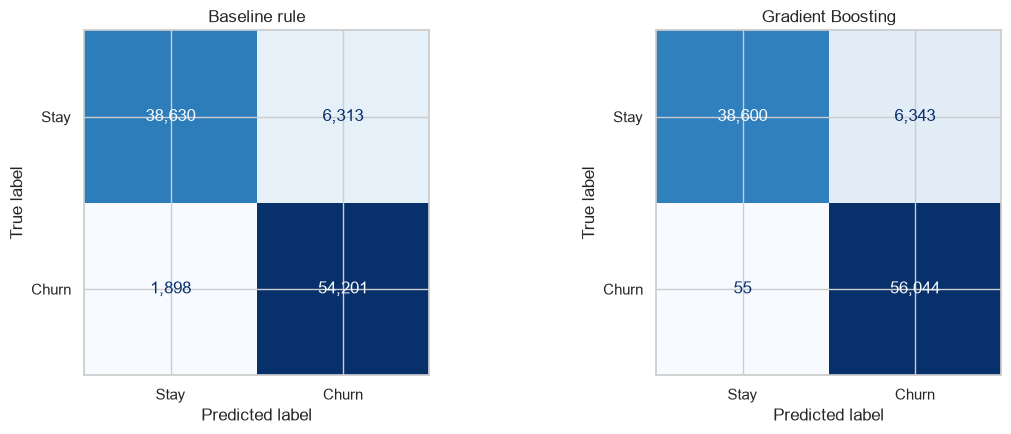

In [22]:
# The 4 cells:  rows = what really happened, columns = what the model predicted.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["Baseline rule", "Gradient Boosting"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred[name], display_labels=["Stay", "Churn"],
        cmap="Blues", values_format=",", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Observation:** (test set, 101,042 customers)

| Cell | Baseline rule | Gradient Boosting | Meaning |
|---|---|---|---|
| True negative (TN) | 38,630 | 38,600 | loyal, correctly left alone |
| False positive (FP) | 6,313 | 6,343 | loyal, but gets a promo (wasted cost) |
| False negative (FN) | 1,898 | 55 | churner we MISSED (lost customer) |
| True positive (TP) | 54,201 | 56,044 | churner caught, can get a promo |

- The big difference is the bottom-left cell: the model misses only 55 churners against 1,898
  for the rule, so about 1,840 more customers can be targeted before they leave.
- Both send ~6,300 unnecessary promos (top-right). The model did not reduce wasted promotions
  at all. 6.4 and 6.5 show where those false positives come from.
- In business terms, if keeping one customer is worth much more than one promo, the model's
  extra ~1,840 caught churners easily justify using it over the rule.

### 6.3 ROC curve and precision-recall curve

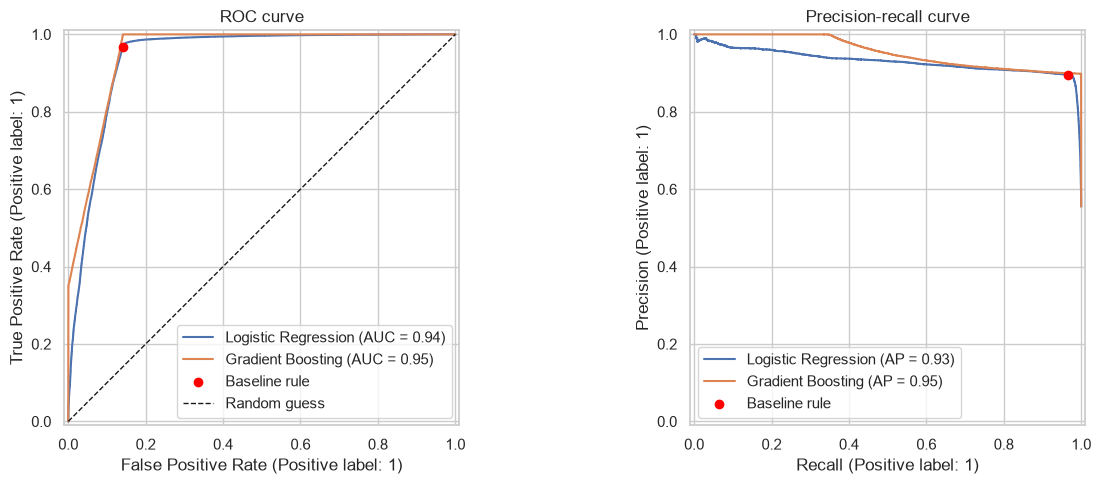

In [23]:
# Both curves show performance at EVERY possible threshold, not just 0.5.
# ROC: true-positive rate (recall) vs false-positive rate. Closer to the top-left = better.
# PR:  precision vs recall. Closer to the top-right = better.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])

# The baseline rule gives only 0/1, so it is a single POINT on each chart, not a curve.
base_recall = recall_score(y_test, baseline_pred_test)
base_fpr = ((baseline_pred_test == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
base_precision = precision_score(y_test, baseline_pred_test)
axes[0].scatter(base_fpr, base_recall, color="red", zorder=5, label="Baseline rule")
axes[1].scatter(base_recall, base_precision, color="red", zorder=5, label="Baseline rule")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[1] else "lower right")
plt.tight_layout()
plt.show()

**Observation:**
- ROC: both models are far above the diagonal "random guess" line. Gradient boosting
  (AUC 0.95) is slightly above logistic regression (0.94).
  AUC = the chance that a random churner gets a higher score than a random loyal customer.
- PR curve: gradient boosting keeps precision at 1.0 up to ~35% recall. Its most confident
  predictions are always right. After that, precision settles at ~0.90 for a long stretch.
  Average precision (AP) 0.95 vs 0.93.
- The baseline rule (red dot) sits right on the models' curves: at its operating point it is
  about as good as the models. The models' advantage is FLEXIBILITY: you can move along the
  curve by choosing a threshold (6.4), while the rule is fixed at one point.
- Both curves have a sharp "corner" instead of a smooth bend. That is a sign of
  near-deterministic (synthetic) data, explored in 6.5.

### 6.4 Choosing the decision threshold

In [24]:
# predict() says "churn" when the probability is >= 0.5. That 0.5 is only a default:
# a LOWER threshold flags more customers (recall up, precision down), a HIGHER one flags fewer.
gbm_proba = test_proba["Gradient Boosting"]
threshold_rows = []
for threshold in [0.3, 0.5, 0.7, 0.8, 0.9]:
    pred_at_t = (gbm_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "flagged_%": pred_at_t.mean() * 100,                                   # share who get a promo
        "recall": recall_score(y_test, pred_at_t),                              # churners caught
        "precision": precision_score(y_test, pred_at_t),                        # flagged who really churn
        "missed_churners": ((pred_at_t == 0) & (y_test == 1)).sum(),            # false negatives
        "wasted_promos": ((pred_at_t == 1) & (y_test == 0)).sum(),              # false positives
    })
print(pd.DataFrame(threshold_rows).round(3).to_string(index=False))

 threshold  flagged_%  recall  precision  missed_churners  wasted_promos
       0.3     61.791   1.000      0.898               23           6359
       0.5     61.744   0.999      0.898               55           6343
       0.7     61.468   0.995      0.898              297           6306
       0.8     60.640   0.982      0.899             1013           6186
       0.9     19.719   0.354      0.997            36227             52


**Observation:**
- Normally, moving the threshold trades recall for precision smoothly. Here it doesn't:
  from 0.3 to 0.8 almost nothing changes (~61% flagged, ~6,300 wasted promos), and then at 0.9
  the model suddenly flags only 20%, catching just 35% of churners (36,227 missed).
- Lowering the threshold (0.3) gains nothing: recall is already ~100% at 0.5.
- Raising it removes the wasted promos (52 at 0.9) but loses most churners. For the business,
  missing churners is the costlier mistake, so the default 0.5 is the sensible choice.
- Why is there a "cliff"? The ~6,300 false positives all have probabilities around 0.85, while
  many real churners sit around 0.75-0.85. The two groups overlap, so no single threshold can
  separate them. 6.5 shows who those 6,300 customers are.

### 6.5 Evaluation per source (A vs B)

In [25]:
# train_test_split kept the original row labels, so we can look up each test row's source.
test_source = source.loc[X_test.index]

source_rows = []
for src in ["A", "B"]:
    in_src = (test_source == src).to_numpy()   # True/False mask over the test rows
    for name in test_pred:
        row = score_row(y_test[in_src], np.asarray(test_pred[name])[in_src],
                        test_proba[name][in_src] if name in test_proba else None)
        source_rows.append({"source": src, "model": name, "rows": in_src.sum(), **row})
source_results = pd.DataFrame(source_rows).set_index(["source", "model"])
print(source_results.round(3))

                             rows  accuracy  precision  recall     f1  roc_auc
source model                                                                  
A      Baseline rule        88273     0.976      0.995   0.962  0.978      NaN
       Logistic Regression  88273     0.933      0.999   0.883  0.937    0.994
       Gradient Boosting    88273     0.999      1.000   0.999  0.999    1.000
B      Baseline rule        12769     0.526      0.500   0.998  0.666      NaN
       Logistic Regression  12769     0.574      0.527   0.991  0.688    0.828
       Gradient Boosting    12769     0.503      0.488   0.999  0.656    0.999


**Observation:** (the most important finding of this project)
- SOURCE A (88,273 test rows, 87% of the test set): gradient boosting is essentially perfect
  (accuracy 0.999, precision 1.000, recall 0.999). Even the simple rule reaches 0.976. As
  predicted in 1.3, source A follows near-perfect rules, so it is "too easy".
- SOURCE B (12,769 rows): at the default threshold every model is barely better than a coin
  flip on its DECISIONS: accuracy 0.50-0.57, precision ~0.50. Gradient boosting flags 97% of
  all source B customers as churners. Almost all of the ~6,340 wasted promos from 6.2 are
  source B customers who stayed.
- Yet gradient boosting's ROC-AUC on B is 0.999: it RANKS B customers almost perfectly
  (B stayers get ~0.85, B churners ~0.99). The problem is the probability SCALE, not the
  ranking. B's "safe" customers score as high as A's churners (~0.75-0.86), so one global
  threshold can't serve both sources (that's the cliff in 6.4).
- So the overall F1 of 0.946 is mostly source A's easy rows. The more honest picture is: the
  model ranks customers very well inside each source, but its yes/no decisions are reliable
  only for source-A-like customers.
- This is exactly why the reference notebook's 99.9% was misleading: by dropping the duplicate
  IDs it removed almost all of source B and evaluated on source A only.

### 6.6 Which features drive the predictions?

support_calls         0.1632
payment_delay         0.0649
age                   0.0506
contract_length       0.0411
gender                0.0288
last_interaction      0.0240
low_spend             0.0149
tenure                0.0113
usage_frequency       0.0085
subscription_type     0.0004
late_payment          0.0000
many_support_calls    0.0000
over_50               0.0000
total_spend          -0.0001
dtype: float64


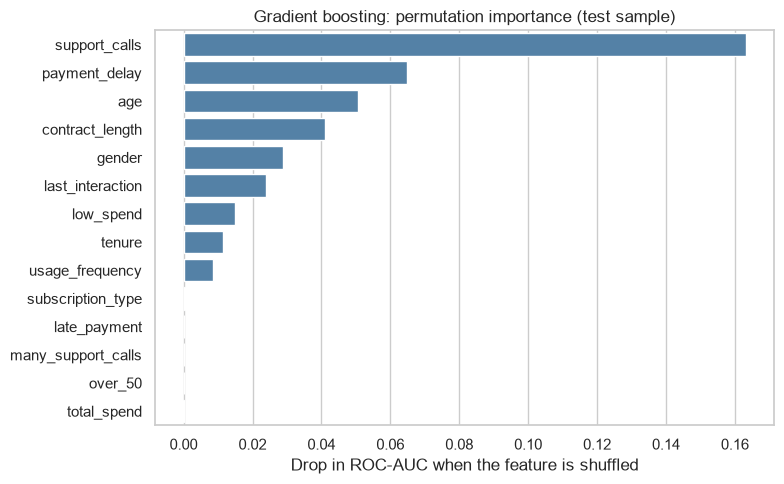

In [26]:
# Permutation importance: shuffle ONE column (break its link with churn) and measure how much
# the score drops. Big drop = the model relies on that feature. It works on the original
# columns, so one-hot columns are grouped back (e.g. "contract_length" as one feature).
# 10,000 test rows are enough and keep it fast.
sample_idx = X_test.sample(10_000, random_state=RANDOM_STATE).index
perm = permutation_importance(gbm, X_test.loc[sample_idx], y_test.loc[sample_idx],
                              scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importance.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, color="steelblue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.ylabel("")
plt.title("Gradient boosting: permutation importance (test sample)")
plt.tight_layout()
plt.show()

**Observation:**
- Top drivers: support_calls (ROC-AUC drops 0.163 when shuffled), payment_delay (0.065),
  age (0.051), contract_length (0.041), gender (0.029), last_interaction (0.024). These are
  the same drivers Project 1 found, so the model learned real patterns, not noise.
- subscription_type is ~0: it doesn't matter, also matching Project 1.
- The engineered flags (late_payment, many_support_calls, over_50) show ~0 importance. That
  doesn't mean they're useless: the tree can get the same information from the raw column
  (payment_delay, support_calls, age). Shuffle a flag alone and the raw column still carries
  the signal. This is a known limitation of permutation importance with overlapping features.
  (For logistic regression in 5.2, the flags were the MOST important, because it can't create
  thresholds itself.)
- The same effect explains total_spend ~0: its threshold is carried by low_spend (0.015).

## 7. Conclusions  (rubric #7)

### 7.1 Results

| Model (test set, 101,042 customers) | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Baseline rule (any of 5 risk flags) | 0.919 | 0.896 | 0.966 | 0.930 | – |
| Logistic Regression | 0.888 | 0.902 | 0.895 | 0.899 | 0.941 |
| **Gradient Boosting** (chosen) | **0.937** | 0.898 | **0.999** | **0.946** | **0.954** |

- **Best model: gradient boosting** (`HistGradientBoostingClassifier`). It catches 99.9% of churners
  and misses only 55 of 56,099, against 1,898 missed by the simple rule.
- **Recall was the main metric**, because a missed churner (a lost customer) costs more than an
  unnecessary promotion. Precision, F1 and ROC-AUC were reported too, not accuracy alone.
- **Logistic regression did not beat the simple rule.** Churn here follows "if ANY risk condition,
  then churn" logic, which trees capture naturally and a single weighted sum does not.
- **No overfitting:** cross-validation (5.4) and test scores agree, with very small fold-to-fold variation.
- **The headline numbers hide a split (6.5):**
  - Source A (87% of the data): near-perfect, accuracy 0.999.
  - Source B (13%): the model *ranks* customers almost perfectly (ROC-AUC 0.999), but at the default
    threshold it flags 97% of them, so its decisions are only ~50% accurate. Almost all of the ~6,300
    wasted promotions are source B customers who stayed.
- **The drivers the model uses** (support calls, payment delay, age, contract length, gender) match
  Mini Project 1's EDA, so it learned real patterns rather than noise.

### 7.2 Pros and cons of the chosen model

**Pros**
- Highest recall and F1: misses almost no churners.
- Learns thresholds and combinations of conditions by itself, with no manual feature work needed.
- Fast: trains in ~10 seconds on 400k rows; stable across folds.
- Doesn't need scaling and isn't sensitive to outliers.

**Cons**
- Harder to explain than a list of weights or 5 simple rules. Permutation importance helps, but
  can't give a simple "why" for one customer.
- Its probabilities aren't on a consistent scale across customer groups: a "0.85" means "loyal"
  for a source B customer but "churner" for a source A customer. So one threshold can't fit everyone.
- Precision is no better than the simple rule (~0.90): it doesn't reduce wasted promotions.
- Its near-perfect scores come largely from synthetic, rule-based data (source A). Real customers
  would be noisier, and real performance would be lower.

### 7.3 How the business would use it

1. **Score customers weekly** with the model and rank them by churn probability.
2. **Prioritise by rank, not just yes/no.** Ranking is the model's strongest skill (ROC-AUC 0.95+, 0.999
   within each source), so give the highest-risk customers the strongest retention offers first.
3. **Use Mini Project 1's actions** on the flagged customers: escalate support cases at the 3rd-4th
   call, step in on payment delays before day 20, offer monthly customers a quarterly plan.
4. **Keep the simple rule as a fallback or explanation tool.** It is nearly as good, and anyone can
   understand "this customer pays late and calls support a lot".
5. **Track results:** the churn rate of contacted vs. not-contacted high-risk customers, to check the
   promotions actually work.

### 7.4 Improvements / next steps

- **Understand what sources A and B really are** (two regions? two systems? two time periods?). If that
  information exists for new customers, it could become a legitimate feature or a reason to use a
  separate threshold per group. That alone would fix most of the wasted promotions in source B.
- **Calibrate the probabilities** (e.g. `CalibratedClassifierCV`) so that "0.8" means an 80% chance of
  churning for every customer group.
- **Choose the threshold from real costs:** with the value of a retained customer and the cost of a
  promotion, pick the threshold that maximises expected profit instead of using 0.5.
- **Test on real, time-based data:** train on past months and test on later months, which is how the
  model would actually be used. A random split can overstate performance.
- **Tune hyperparameters** (`learning_rate`, `max_depth`, number of trees) with cross-validation. Expect
  small gains here, since the model is already near the ceiling on this data.
- **Explain individual predictions** (e.g. SHAP values) so the retention team can see *why* a specific
  customer was flagged.
- **Monitor and retrain:** customer behaviour changes, so track the model's recall and precision over
  time and retrain when they drop.